#Scraping the dataset webpage

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup

url = "https://www.kaggle.com/datasets/sushantchougule/kolkata-shops-sales"

response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=30
)

print("Status Code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")

print("Page Title:", soup.title.get_text(strip=True)
      if soup.title else "Title not found")

Status Code: 200
Page Title: Grocery Sales Prediction | Kaggle


In [111]:
import requests
import pandas as pd
from pathlib import Path
from zipfile import ZipFile

dataset = "sushantchougule/kolkata-shops-sales"
download_dir = Path("kolkata_shops_sales")
download_dir.mkdir(parents=True, exist_ok=True)

import subprocess

result = subprocess.run(
    [
        "kaggle", "datasets", "download",
        "-d", dataset,
        "-p", str(download_dir)
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("Download Error:", result.stderr)
else:
    zip_files = list(download_dir.glob("*.zip"))

    if zip_files:
        with ZipFile(zip_files[0]) as archive:
            archive.extractall(download_dir)

    csv_files = list(download_dir.glob("*.csv"))

    if csv_files:
        df = pd.read_csv(csv_files[0])

        print("Dataset downloaded successfully!")
        print("Dataset File:", csv_files[0].name)
        print("Dataset Shape:", df.shape)
        print("\nColumn Names:", df.columns.tolist())
        print("\nFirst Five Rows:")
        print(df.head())
    else:
        print("No CSV file found in the downloaded dataset.")

Dataset URL: https://www.kaggle.com/datasets/sushantchougule/kolkata-shops-sales
License(s): apache-2.0
kolkata-shops-sales.zip: Skipping, found more recently modified local copy (use --force to force download)

Dataset downloaded successfully!
Dataset File: K_class_sales_clean.csv
Dataset Shape: (8523, 13)

Column Names: ['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Identifier', 'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type', 'Item_Outlet_Sales', 'Profit']

First Five Rows:
  Item_Identifier  Item_Weight Item_Fat_Content  Item_Visibility  \
0           FDA15         9.30          Low Fat         0.016047   
1           DRC01         5.92          Regular         0.019278   
2           FDN15        17.50          Low Fat         0.016760   
3           FDX07        19.20          Regular         0.000000   
4           NCD19         8.93          Low Fat         0.000000   

               

In [112]:
# Check dataset information
print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Fill missing numerical values with median
for column in df.select_dtypes(include=np.number).columns:
    df[column] = df[column].fillna(df[column].median())

# Fill missing categorical values with mode
for column in df.select_dtypes(include="object").columns:
    if df[column].isnull().any() and not df[column].mode().empty:
        df[column] = df[column].fillna(df[column].mode()[0])

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

df.to_csv("cleaned_kolkata_shops_sales.csv", index=False)

print("\nCleaned dataset saved successfully!")

Dataset Shape: (8523, 13)

Data Types:
Item_Identifier               object
Item_Weight                  float64
Item_Fat_Content              object
Item_Visibility              float64
Item_Type                     object
Item_MRP                     float64
Outlet_Identifier             object
Outlet_Establishment_Year      int64
Outlet_Size                   object
Outlet_Location_Type          object
Outlet_Type                   object
Item_Outlet_Sales            float64
Profit                       float64
dtype: object

Missing Values:
Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
Profit                       0
dtype: int64

Duplicate Rows: 0

Missing Value

# Data cleaning and preprocessing

In [35]:
# Check dataset information
print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Fill missing numerical values with median
for column in df.select_dtypes(include=np.number).columns:
    df[column] = df[column].fillna(df[column].median())

# Fill missing categorical values with mode
for column in df.select_dtypes(include="object").columns:
    if df[column].isnull().any() and not df[column].mode().empty:
        df[column] = df[column].fillna(df[column].mode()[0])

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

df.to_csv("cleaned_kolkata_shops_sales.csv", index=False)

print("\nCleaned dataset saved successfully!")

Dataset Shape: (8523, 13)

Data Types:
Item_Identifier               object
Item_Weight                  float64
Item_Fat_Content              object
Item_Visibility              float64
Item_Type                     object
Item_MRP                     float64
Outlet_Identifier             object
Outlet_Establishment_Year      int64
Outlet_Size                   object
Outlet_Location_Type          object
Outlet_Type                   object
Item_Outlet_Sales            float64
Profit                       float64
dtype: object

Missing Values:
Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
Profit                       0
dtype: int64

Duplicate Rows: 0

Missing Value

#Descriptive statistics

In [37]:
numeric_df = df.select_dtypes(include=np.number)

print("Mean:")
print(numeric_df.mean())

print("\nMedian:")
print(numeric_df.median())

print("\nMode:")
print(numeric_df.mode().head(1))

print("\nVariance:")
print(numeric_df.var())

print("\nStandard Deviation:")
print(numeric_df.std())

print("\nQuartiles:")
print(numeric_df.quantile([0.25, 0.50, 0.75]))

print("\nSummary Statistics:")
print(numeric_df.describe())

Mean:
Item_Weight                    11.688100
Item_Visibility                 0.066132
Item_MRP                      140.998838
Outlet_Establishment_Year    1997.831867
Item_Outlet_Sales            2181.288914
Profit                         13.414514
dtype: float64

Median:
Item_Weight                    11.688100
Item_Visibility                 0.053931
Item_MRP                      142.700000
Outlet_Establishment_Year    1999.000000
Item_Outlet_Sales            1794.331000
Profit                         13.900000
dtype: float64

Mode:
   Item_Weight  Item_Visibility  Item_MRP  Outlet_Establishment_Year  \
0      11.6881              0.0     139.6                       1985   

   Item_Outlet_Sales  Profit  
0            958.752    14.3  

Variance:
Item_Weight                  3.135421e+01
Item_Visibility              2.662335e-03
Item_MRP                     3.876071e+03
Outlet_Establishment_Year    7.008637e+01
Item_Outlet_Sales            2.912141e+06
Profit                      

#Data visualization

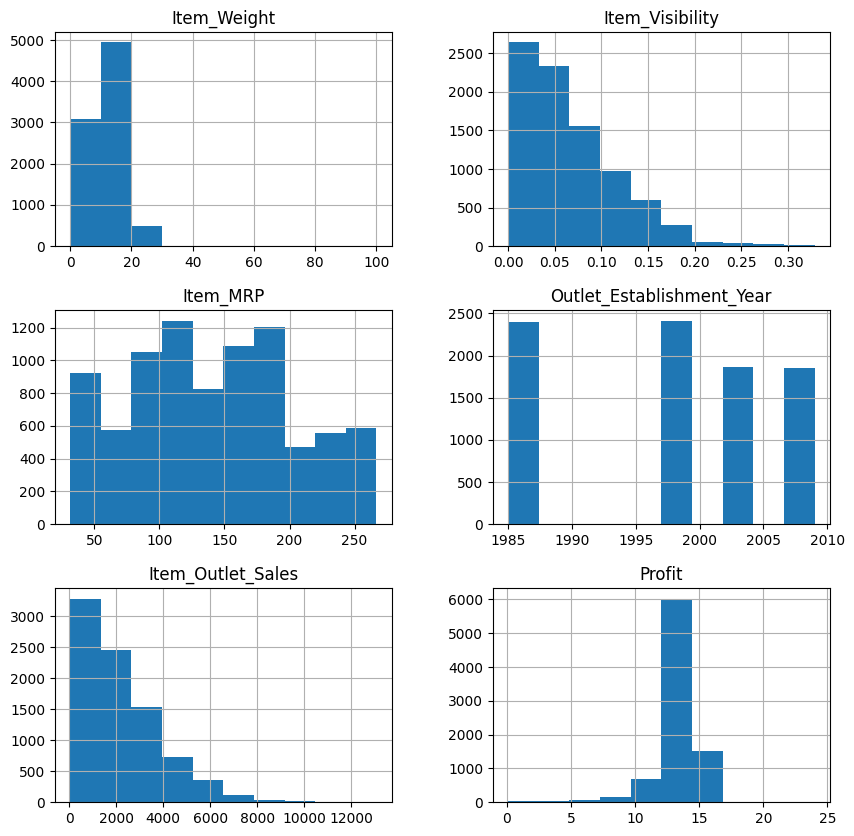

In [40]:
df.select_dtypes(include=np.number).hist(figsize=(10, 10))
plt.show()

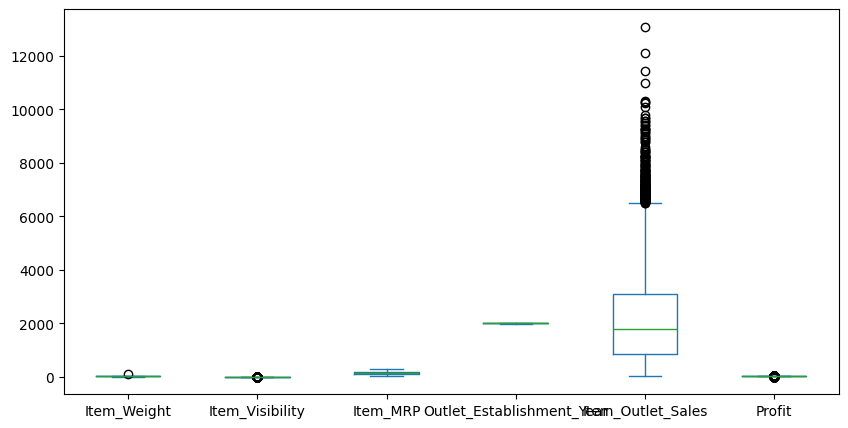

In [43]:
df.select_dtypes(include=np.number).plot(
    kind="box", figsize=(10,5)
)
plt.show()

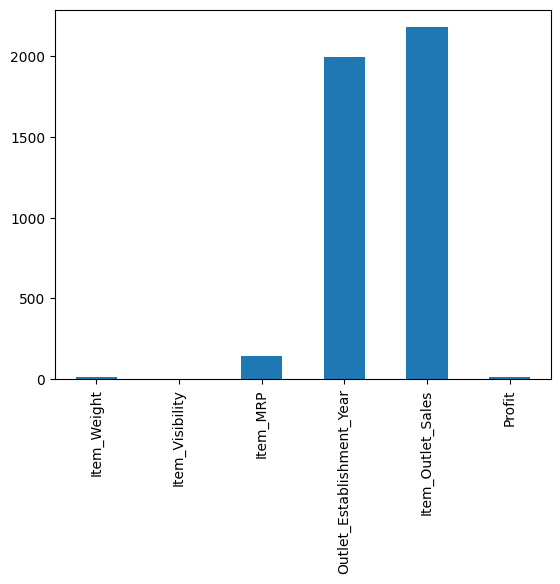

In [44]:
df.select_dtypes(include=np.number).mean().plot(kind="bar")
plt.show()

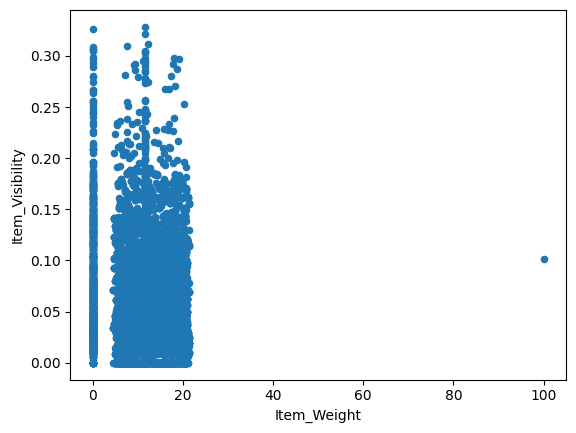

In [45]:
df.plot(
    kind="scatter",
    x=df.select_dtypes(include=np.number).columns[0],
    y=df.select_dtypes(include=np.number).columns[1]
)
plt.show()

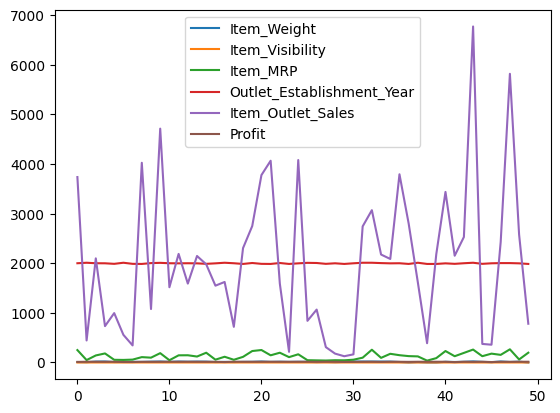

In [46]:
df.select_dtypes(include=np.number).head(50).plot(kind="line")
plt.show()

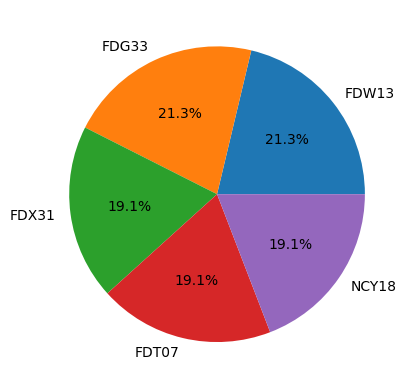

In [47]:
df.select_dtypes(include="object").iloc[:, 0].value_counts().head(5).plot(
    kind="pie", autopct="%1.1f%%"
)
plt.ylabel("")
plt.show()

# Normal Distribution

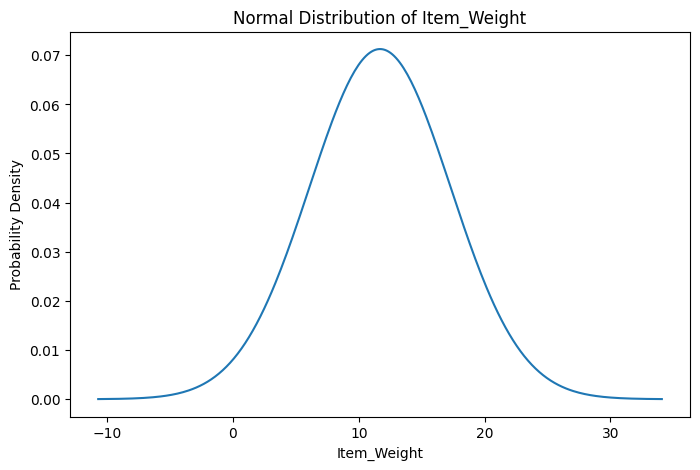

In [50]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Select the first numerical column
numeric_columns = df.select_dtypes(include=np.number).columns
data = df[numeric_columns[0]].dropna()

# Calculate mean and standard deviation
mean_value = data.mean()
std_value = data.std()

# Generate values for the normal distribution
x = np.linspace(
    mean_value - 4 * std_value,
    mean_value + 4 * std_value,
    300
)

y = stats.norm.pdf(x, mean_value, std_value)

# Plot normal distribution
plt.figure(figsize=(8, 5))
plt.plot(x, y)

plt.title("Normal Distribution of " + numeric_columns[0])
plt.xlabel(numeric_columns[0])
plt.ylabel("Probability Density")

plt.show()

#Uniform distribution

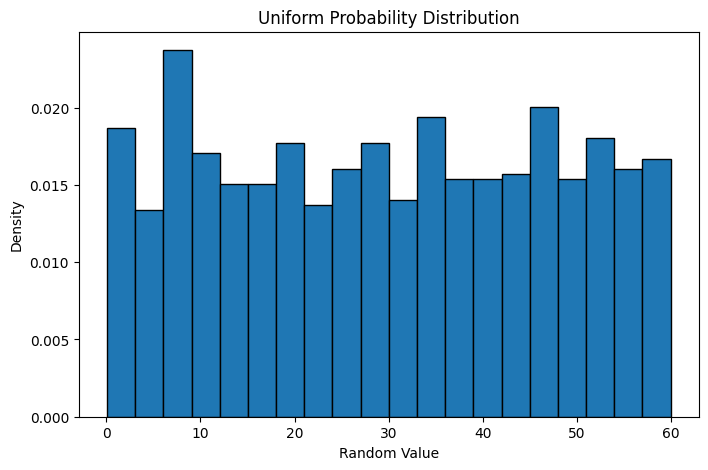

In [51]:
# Generate 1000 random values between 0 and 60
uniform_data = np.random.default_rng(42).uniform(
    low=0,
    high=60,
    size=1000
)

# Plot uniform distribution
plt.figure(figsize=(8, 5))

plt.hist(
    uniform_data,
    bins=20,
    density=True,
    edgecolor="black"
)

plt.title("Uniform Probability Distribution")
plt.xlabel("Random Value")
plt.ylabel("Density")

plt.show()

#Binomial distribution

Probability of value above median: 0.46485979115334974


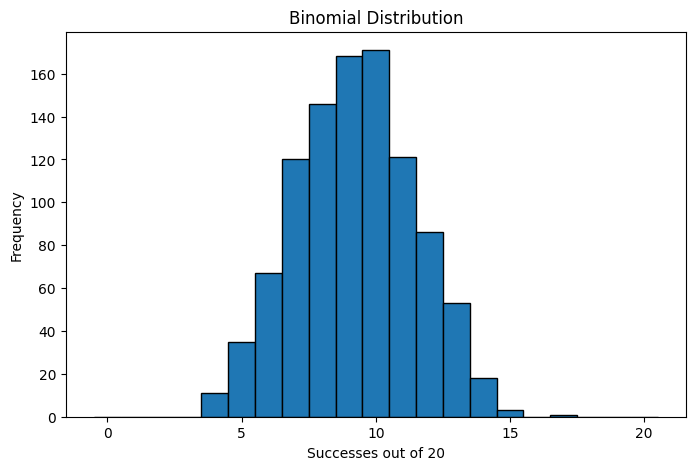

In [52]:
# Select a numerical column
numeric_columns = df.select_dtypes(include=np.number).columns
data = df[numeric_columns[0]].dropna()

# Calculate the probability that a value is above the median
median_value = data.median()
p = (data > median_value).mean()

print("Probability of value above median:", p)

# Generate binomial random values
binomial_data = stats.binom.rvs(
    n=20,
    p=p,
    size=1000,
    random_state=42
)

# Plot binomial distribution
plt.figure(figsize=(8, 5))

plt.hist(
    binomial_data,
    bins=np.arange(-0.5, 21.5, 1),
    edgecolor="black"
)

plt.title("Binomial Distribution")
plt.xlabel("Successes out of 20")
plt.ylabel("Frequency")

plt.show()

#Simple random sampling

In [53]:
# Select a random sample of up to 100 rows
simple_sample = df.sample(
    n=min(100, len(df)),
    random_state=42
)

# Display the sample
print("Simple Random Sample:")
display(simple_sample.head())

print("Sample size:", len(simple_sample))

# Calculate sample mean for the first numerical column
column = df.select_dtypes(include=np.number).columns[0]

print("Sample mean of", column, ":",
      simple_sample[column].mean())

Simple Random Sample:


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,Profit
7503,FDI28,14.3000,Low Fat,0.026300,Frozen Foods,79.4,OUT013,1987,High,Tier 3,Supermarket Type1,1743.0644,14.0
2957,NCM17,7.9300,Low Fat,0.071136,Health and Hygiene,42.7,OUT046,1997,Small,Tier1,Supermarket Type1,356.8688,10.3
7031,FDC14,14.5000,Regular,0.041313,Canned,42.0,OUT049,1999,Medium,Tier 2,Supermarket Type1,377.5086,13.8
1084,DRC36,11.6881,Regular,0.044767,Soft Drinks,173.7,OUT027,1985,Medium,Tier 2,Supermarket Type3,5778.4782,14.7
856,FDS27,10.1950,Regular,0.012456,Meat,197.5,OUT035,2004,Small,Tier1,Supermarket Type1,2356.9320,13.2


Sample size: 100
Sample mean of Item_Weight : 11.503990964630221


#Systematic sampling

In [54]:
# Select every 10th row after a random starting position
k = 10
rng = np.random.default_rng(42)

start = rng.integers(0, min(k, len(df)))

systematic_sample = df.iloc[start::k]

# Display the sample
print("Systematic Sample:")
display(systematic_sample.head())

print("Sample size:", len(systematic_sample))

column = df.select_dtypes(include=np.number).columns[0]

print("Sample mean of", column, ":",
      systematic_sample[column].mean())

Systematic Sample:


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,Profit
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8,OUT049,1999,Medium,Tier 2,Supermarket Type1,3735.1380,11.5
10,FDY07,11.80,Low Fat,0.000000,Fruits and Vegetables,45.5,OUT049,1999,Medium,Tier 2,Supermarket Type1,1516.0266,14.3
20,FDN22,18.85,Regular,0.138190,Snack Foods,250.9,OUT013,1987,High,Tier 3,Supermarket Type1,3775.0860,14.6
30,FDV38,19.25,Low Fat,0.170349,Dairy,55.8,OUT010,1998,Medium,Tier 2,Grocery Store,163.7868,11.7
40,FDU02,13.35,Low Fat,0.102512,Dairy,230.6,OUT046,1997,Small,Tier1,Supermarket Type1,3435.5280,14.2


Sample size: 853
Sample mean of Item_Weight : 11.613898334985656


#Stratified sampling

In [55]:
# Select the first numerical column
column = df.select_dtypes(include=np.number).columns[0]

# Create groups based on quartiles
df["Value_Group"] = pd.qcut(
    df[column],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"],
    duplicates="drop"
)

# Take a 10% sample from each group
stratified_sample = (
    df.dropna(subset=["Value_Group"])
    .groupby(
        "Value_Group",
        observed=True,
        group_keys=False
    )
    .sample(frac=0.10, random_state=42)
)

# Display the sample
print("Stratified Sample:")
display(stratified_sample.head())

print("Sample size:", len(stratified_sample))

print("\nRecords from each group:")
print(stratified_sample["Value_Group"].value_counts())

Stratified Sample:


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,Profit,Value_Group
6247,FDX47,6.550,Regular,0.034745,Breads,158.8,OUT018,2009,Medium,Tier 2,Supermarket Type2,4399.6064,6.0,Low
863,FDA51,8.050,Regular,0.164543,Dairy,112.3,OUT013,1987,High,Tier 3,Supermarket Type1,1707.7770,14.5,Low
1806,FDN25,7.895,Regular,0.061125,Breakfast,58.6,OUT013,1987,High,Tier 3,Supermarket Type1,171.7764,14.0,Low
1161,NCR29,7.565,Low Fat,0.054863,Health and Hygiene,58.4,OUT018,2009,Medium,Tier 2,Supermarket Type2,509.3370,14.1,Low
7753,DRL60,0.000,Low Fat,0.047377,Soft Drinks,150.7,OUT019,1985,Small,Tier1,Grocery Store,457.4046,14.6,Low


Sample size: 852

Records from each group:
Value_Group
Medium-Low     242
Low            214
High           212
Medium-High    184
Name: count, dtype: int64


#Compare population and sample means

In [56]:
# Select the numerical column used for sampling
column = df.select_dtypes(include=np.number).columns[0]

# Compare the population mean and sample means
print("Population Mean:", df[column].mean())

print("Simple Random Sample Mean:",
      simple_sample[column].mean())

print("Systematic Sample Mean:",
      systematic_sample[column].mean())

print("Stratified Sample Mean:",
      stratified_sample[column].mean())

Population Mean: 11.688099678456592
Simple Random Sample Mean: 11.503990964630221
Systematic Sample Mean: 11.613898334985656
Stratified Sample Mean: 11.736766869706987


#Distribution of sampled data

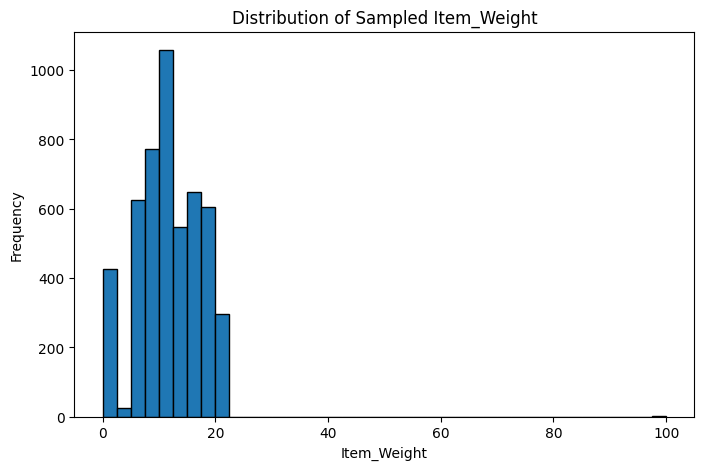

In [57]:
# Select up to 5000 non-missing values
column = df.select_dtypes(include=np.number).columns[0]

plot_data = df[column].dropna().sample(
    n=min(5000, df[column].dropna().shape[0]),
    random_state=42
)

# Plot the distribution
plt.figure(figsize=(8, 5))

plt.hist(plot_data, bins=40, edgecolor="black")

plt.title("Distribution of Sampled " + column)
plt.xlabel(column)
plt.ylabel("Frequency")

plt.show()

# Save all sampling datasets

In [58]:
# Save the three sampling datasets as CSV files
simple_sample.to_csv(
    "simple_random_sample.csv",
    index=False
)

systematic_sample.to_csv(
    "systematic_sample.csv",
    index=False
)

stratified_sample.to_csv(
    "stratified_sample.csv",
    index=False
)

print("All sampling datasets saved successfully!")

All sampling datasets saved successfully!


In [60]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select the first numerical column from the Kaggle dataset
column = df.select_dtypes(include=np.number).columns[0]

# Remove missing values and convert data into an array
population = df[column].dropna().to_numpy()

# Calculate population statistics
population_mean = np.mean(population)
population_std = np.std(population, ddof=0)

print("Selected Column:", column)
print("Population Size:", len(population))
print("Population Mean:", population_mean)
print("Population Standard Deviation:", population_std)

Selected Column: Item_Weight
Population Size: 8523
Population Mean: 11.688099678456592
Population Standard Deviation: 5.599154864674627


#2: Draw a random sample

In [61]:
# Create a random number generator
rng = np.random.default_rng(42)

# Select a sample of up to 30 observations
sample_size = min(30, len(population))

sample = rng.choice(
    population,
    size=sample_size,
    replace=False
)

# Display sample statistics
print("Sample Size:", len(sample))
print("Sample Mean:", np.mean(sample))
print("Population Mean:", population_mean)

Sample Size: 30
Sample Mean: 11.201579957127551
Population Mean: 11.688099678456592


# Repeated sampling for the CLT

In [62]:
# Set sample size and number of repeated samples
rng = np.random.default_rng(42)

sample_size = min(30, len(population))
number_of_samples = 1000

sample_means = []

# Draw repeated samples and calculate their means
for i in range(number_of_samples):
    sample = rng.choice(
        population,
        size=sample_size,
        replace=True
    )

    sample_means.append(np.mean(sample))

sample_means = np.array(sample_means)

print("Number of Samples:", number_of_samples)
print("Mean of Sample Means:", sample_means.mean())
print("Population Mean:", population_mean)

Number of Samples: 1000
Mean of Sample Means: 11.72827600589496
Population Mean: 11.688099678456592


#Plot the sampling distribution

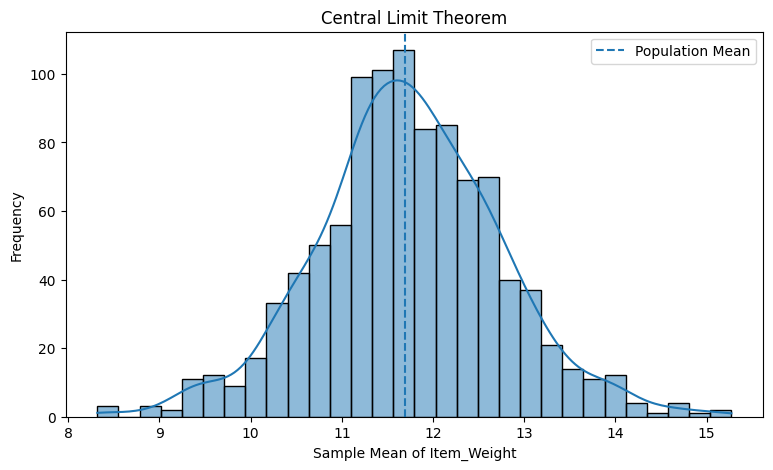

In [63]:
# Plot the distribution of repeated sample means
plt.figure(figsize=(9, 5))

sns.histplot(sample_means, bins=30, kde=True)

# Show the population mean
plt.axvline(
    population_mean,
    linestyle="--",
    label="Population Mean"
)

plt.title("Central Limit Theorem")
plt.xlabel("Sample Mean of " + column)
plt.ylabel("Frequency")
plt.legend()

plt.show()

# Compare different sample sizes

In [64]:
# Test different sample sizes
rng = np.random.default_rng(42)

sample_sizes = [5, 15, 30, 50, 100]
results = []

for n in sample_sizes:

    # Skip sample sizes larger than the population
    if n > len(population):
        continue

    means = []

    # Calculate 1000 sample means for each sample size
    for i in range(1000):
        sample = rng.choice(
            population,
            size=n,
            replace=True
        )

        means.append(np.mean(sample))

    # Store the results
    results.append({
        "Sample Size": n,
        "Mean of Sample Means": np.mean(means),
        "Standard Deviation of Sample Means": np.std(
            means, ddof=1
        )
    })

clt_results = pd.DataFrame(results)

display(clt_results)

,Sample Size,Mean of Sample Means,Standard Deviation of Sample Means
0,5,11.813400,2.433063
1,15,11.736364,1.477891
2,30,11.646797,0.973575
3,50,11.656993,0.770605
4,100,11.699266,0.537414


#Plot sample size versus standard error

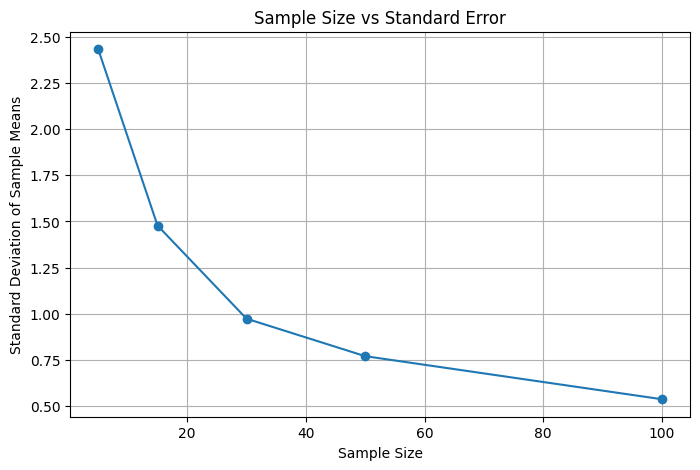

In [65]:
# Plot how the spread of sample means changes with sample size
plt.figure(figsize=(8, 5))

plt.plot(
    clt_results["Sample Size"],
    clt_results["Standard Deviation of Sample Means"],
    marker="o"
)

plt.title("Sample Size vs Standard Error")
plt.xlabel("Sample Size")
plt.ylabel("Standard Deviation of Sample Means")

plt.grid(True)
plt.show()

#Calculate theoretical standard error

In [66]:
# Calculate theoretical standard error for each sample size
for n in clt_results["Sample Size"]:

    standard_error = population_std / np.sqrt(n)

    print(
        "Sample Size:", n,
        "| Theoretical Standard Error:",
        round(standard_error, 3)
    )

Sample Size: 5 | Theoretical Standard Error: 2.504
Sample Size: 15 | Theoretical Standard Error: 1.446
Sample Size: 30 | Theoretical Standard Error: 1.022
Sample Size: 50 | Theoretical Standard Error: 0.792
Sample Size: 100 | Theoretical Standard Error: 0.56


#Point estimation of population parameters

In [67]:
# Draw a sample to estimate population parameters
rng = np.random.default_rng(100)

sample_size = min(100, len(population))

sample = rng.choice(
    population,
    size=sample_size,
    replace=False
)

# Estimate population mean, variance, and standard deviation
mean_estimate = np.mean(sample)
variance_estimate = np.var(sample, ddof=1)
std_estimate = np.std(sample, ddof=1)

print("Estimated Population Mean:", mean_estimate)
print("Estimated Population Variance:", variance_estimate)
print("Estimated Population Standard Deviation:", std_estimate)

Estimated Population Mean: 12.351883954983924
Estimated Population Variance: 30.998824126975677
Estimated Population Standard Deviation: 5.567658765313808


#Calculate the 95% confidence interval

In [68]:
# Calculate sample statistics
n = len(data)
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)

# Calculate standard error
standard_error = sample_std / np.sqrt(n)

# Calculate 95% confidence interval using t-distribution
confidence_interval = stats.t.interval(
    0.95,
    df=n-1,
    loc=sample_mean,
    scale=standard_error
)

print("Sample Mean:", sample_mean)
print("95% Confidence Interval:", confidence_interval)

Sample Mean: 11.688099678456592
95% Confidence Interval: (np.float64(11.56920525314116), np.float64(11.806994103772023))


#  one-sample Z-test

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm, t
# Set the hypothesized population mean
population_mean = round(sample_mean)

# Assume population standard deviation is known
population_std = sample_std

# Calculate Z-statistic
z_value = (sample_mean - population_mean) / (
    population_std / np.sqrt(n)
)

# Calculate two-tailed p-value
p_value = 2 * (1 - norm.cdf(abs(z_value)))

print("Hypothesized Mean:", population_mean)
print("Z-statistic:", z_value)
print("P-value:", p_value)

# Make a decision at 5% significance level
if p_value < 0.05:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Hypothesized Mean: 12
Z-statistic: -5.14237931056526
P-value: 2.712807105620385e-07
Reject the null hypothesis


# one-sample t-test

In [ ]:
# Set the hypothesized population mean
population_mean = round(sample_mean)

# Perform one-sample t-test
t_value, p_value = stats.ttest_1samp(
    data,
    population_mean
)

print("Hypothesized Mean:", population_mean)
print("T-statistic:", t_value)
print("P-value:", p_value)

# Make a decision at 5% significance level
if p_value < 0.05:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

#Plot

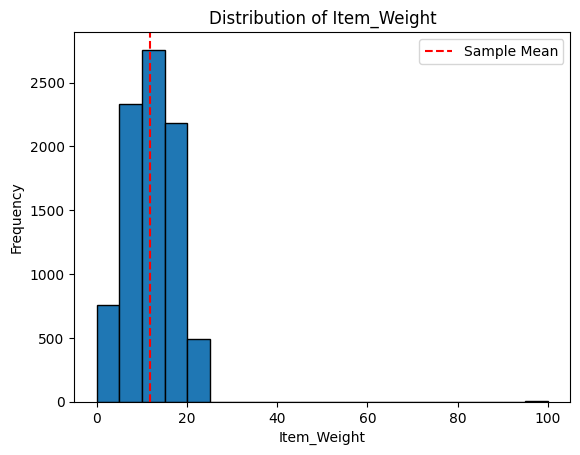

In [72]:
# Plot the selected numerical column
plt.hist(data, bins=20, edgecolor="black")

plt.axvline(
    sample_mean,
    color="red",
    linestyle="dashed",
    label="Sample Mean"
)

plt.xlabel(column)
plt.ylabel("Frequency")
plt.title("Distribution of " + column)
plt.legend()
plt.show()

#final results

In [73]:
# Display summary of statistical results
print("----- FINAL RESULTS -----")
print("Column:", column)
print("Sample Size:", n)
print("Sample Mean:", sample_mean)
print("Sample Standard Deviation:", sample_std)
print("95% Confidence Interval:", confidence_interval)
print("Z-test P-value:", 2 * (1 - norm.cdf(abs(z_value))))
print("T-test P-value:", p_value)

----- FINAL RESULTS -----
Column: Item_Weight
Sample Size: 8523
Sample Mean: 11.688099678456592
Sample Standard Deviation: 5.599483366823091
95% Confidence Interval: (np.float64(11.56920525314116), np.float64(11.806994103772023))
Z-test P-value: 2.712807105620385e-07
T-test P-value: 2.712807105620385e-07


#Import libraries and select columns

In [74]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, f_oneway

# Display column names
print("Columns:", df.columns.tolist())

# Select categorical and numerical columns
categorical_columns = df.select_dtypes(include="object").columns
numerical_columns = df.select_dtypes(include=np.number).columns

print("Categorical Columns:", categorical_columns.tolist())
print("Numerical Columns:", numerical_columns.tolist())

Columns: ['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Identifier', 'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type', 'Item_Outlet_Sales', 'Profit', 'Value_Group']
Categorical Columns: ['Item_Identifier', 'Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']
Numerical Columns: ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year', 'Item_Outlet_Sales', 'Profit']


#Chi-Square test

In [75]:
# Select two categorical columns
cat1 = categorical_columns[0]
cat2 = categorical_columns[1]

# Create a contingency table
table = pd.crosstab(df[cat1], df[cat2])

print("Contingency Table:")
print(table)

# Perform Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

# Make a decision
if p_value < 0.05:
    print("Reject the null hypothesis: Variables are associated.")
else:
    print("Fail to reject the null hypothesis: No significant association found.")

Contingency Table:
Item_Fat_Content  LF  Low Fat  Regular  low fat  reg
Item_Identifier                                     
DRA12              1        5        0        0    0
DRA24              0        0        7        0    0
DRA59              0        0        8        0    0
DRB01              0        3        0        0    0
DRB13              0        0        5        0    0
...               ..      ...      ...      ...  ...
NCZ30              1        6        0        0    0
NCZ41              0        5        0        0    0
NCZ42              1        4        0        0    0
NCZ53              0        5        0        0    0
NCZ54              0        7        0        0    0

[1559 rows x 5 columns]
Chi-Square Statistic: 13064.804093622697
P-value: 0.0
Degrees of Freedom: 6232
Reject the null hypothesis: Variables are associated.


#One-Way ANOVA test

In [77]:
# Select one numerical and one categorical column
num_col = numerical_columns[0]
cat_col = categorical_columns[0]

# Create groups based on categories
groups = []

for category in df[cat_col].dropna().unique():
    values = df[df[cat_col] == category][num_col].dropna()

    if len(values) > 1:
        groups.append(values)

# Perform One-Way ANOVA
f_statistic, p_value = f_oneway(*groups)

print("Numerical Column:", num_col)
print("Grouping Column:", cat_col)
print("F-statistic:", f_statistic)
print("P-value:", p_value)

# Make a decision
if p_value < 0.05:
    print("Reject the null hypothesis: Group means differ significantly.")
else:
    print("Fail to reject the null hypothesis: No significant difference found.")

Numerical Column: Item_Weight
Grouping Column: Item_Identifier
F-statistic: 5.162543184024703
P-value: 0.0
Reject the null hypothesis: Group means differ significantly.


#correlation

In [80]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_data = df.select_dtypes(include=np.number)

print("Numerical Columns:")
print(numeric_data.columns.tolist())

Numerical Columns:
['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year', 'Item_Outlet_Sales', 'Profit']


In [81]:
# Calculate correlation between numerical variables
correlation = numeric_data.corr()

print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
                           Item_Weight  Item_Visibility  Item_MRP  \
Item_Weight                   1.000000        -0.049299  0.020638   
Item_Visibility              -0.049299         1.000000 -0.001597   
Item_MRP                      0.020638        -0.001597  1.000000   
Outlet_Establishment_Year     0.313914        -0.074834  0.005046   
Item_Outlet_Sales            -0.030432        -0.128625  0.567555   
Profit                       -0.015444         0.014269  0.004109   

                           Outlet_Establishment_Year  Item_Outlet_Sales  \
Item_Weight                                 0.313914          -0.030432   
Item_Visibility                            -0.074834          -0.128625   
Item_MRP                                    0.005046           0.567555   
Outlet_Establishment_Year                   1.000000          -0.049135   
Item_Outlet_Sales                          -0.049135           1.000000   
Profit                                     -0.

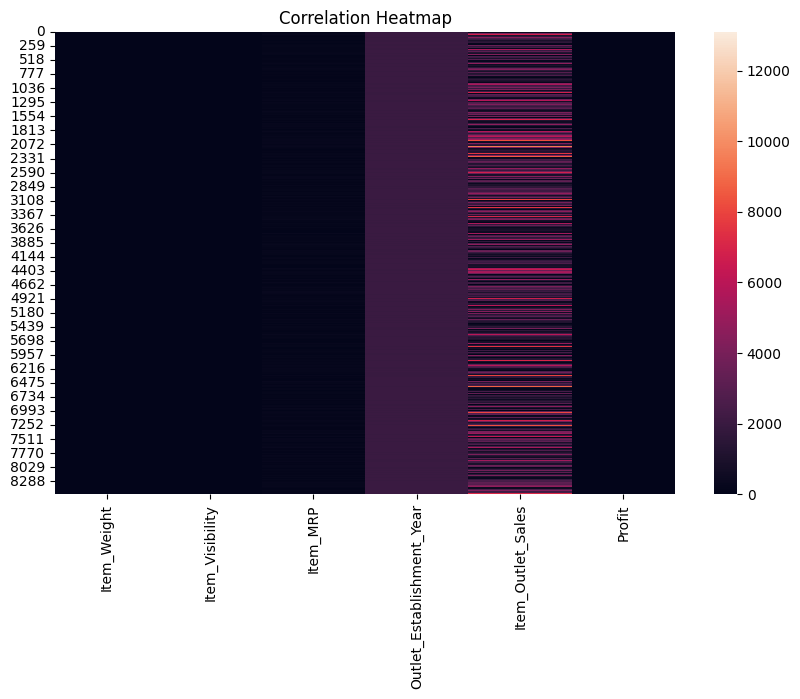

In [85]:
# Plot correlation heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(numeric_data)

plt.title("Correlation Heatmap")
plt.show()

#Covariance

In [87]:
# Calculate covariance between numerical variables
covariance = numeric_data.cov()

print("Covariance Matrix:")
print(covariance)

Covariance Matrix:
                           Item_Weight  Item_Visibility      Item_MRP  \
Item_Weight                  31.354214        -0.014243      7.194711   
Item_Visibility              -0.014243         0.002662     -0.005131   
Item_MRP                      7.194711        -0.005131   3876.070885   
Outlet_Establishment_Year    14.715529        -0.032325      2.629821   
Item_Outlet_Sales          -290.795014       -11.325611  60299.006078   
Profit                       -0.147177         0.001253      0.435364   

                           Outlet_Establishment_Year  Item_Outlet_Sales  \
Item_Weight                                14.715529      -2.907950e+02   
Item_Visibility                            -0.032325      -1.132561e+01   
Item_MRP                                    2.629821       6.029901e+04   
Outlet_Establishment_Year                  70.086372      -7.019621e+02   
Item_Outlet_Sales                        -701.962133       2.912141e+06   
Profit             

In [88]:
# Select the first two numerical columns
x = numeric_data.columns[0]
y = numeric_data.columns[1]

# Calculate covariance
value = numeric_data[x].cov(numeric_data[y])

print("Variable 1:", x)
print("Variable 2:", y)
print("Covariance:", value)

if value > 0:
    print("Both variables tend to move in the same direction")
elif value < 0:
    print("Variables tend to move in opposite directions")
else:
    print("No linear co-movement indicated by covariance")

Variable 1: Item_Weight
Variable 2: Item_Visibility
Covariance: -0.014243383746915944
Variables tend to move in opposite directions


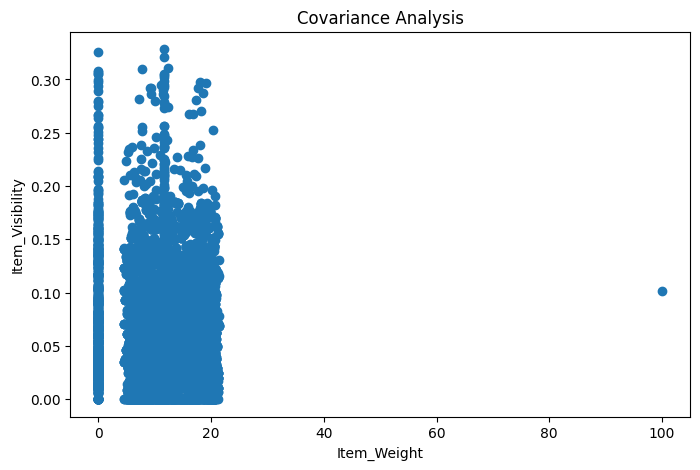

In [89]:
# Create a scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(numeric_data[x], numeric_data[y])

plt.xlabel(x)
plt.ylabel(y)
plt.title("Covariance Analysis")
plt.show()

##Spearman Correlation Analysis

In [92]:
from scipy.stats import spearmanr
# Select numerical columns from the dataset
numeric_data = df.select_dtypes(include=np.number)

print("Numerical Columns:")
print(numeric_data.columns)

Numerical Columns:
Index(['Item_Weight', 'Item_Visibility', 'Item_MRP',
       'Outlet_Establishment_Year', 'Item_Outlet_Sales', 'Profit'],
      dtype='object')


In [93]:
# Select the first two numerical columns
x = numeric_data.columns[0]
y = numeric_data.columns[1]

# Remove missing values
data = numeric_data[[x, y]].dropna()

# Calculate Spearman correlation
correlation, p_value = spearmanr(data[x], data[y])

print("Variable 1:", x)
print("Variable 2:", y)
print("Spearman Correlation:", round(correlation, 4))
print("P-value:", round(p_value, 4))

Variable 1: Item_Weight
Variable 2: Item_Visibility
Spearman Correlation: -0.0275
P-value: 0.0113


In [94]:
if correlation > 0:
    print("Positive relationship between the variables.")
elif correlation < 0:
    print("Negative relationship between the variables.")
else:
    print("No monotonic relationship.")

if p_value < 0.05:
    print("The relationship is statistically significant.")
else:
    print("The relationship is not statistically significant.")

Negative relationship between the variables.
The relationship is statistically significant.


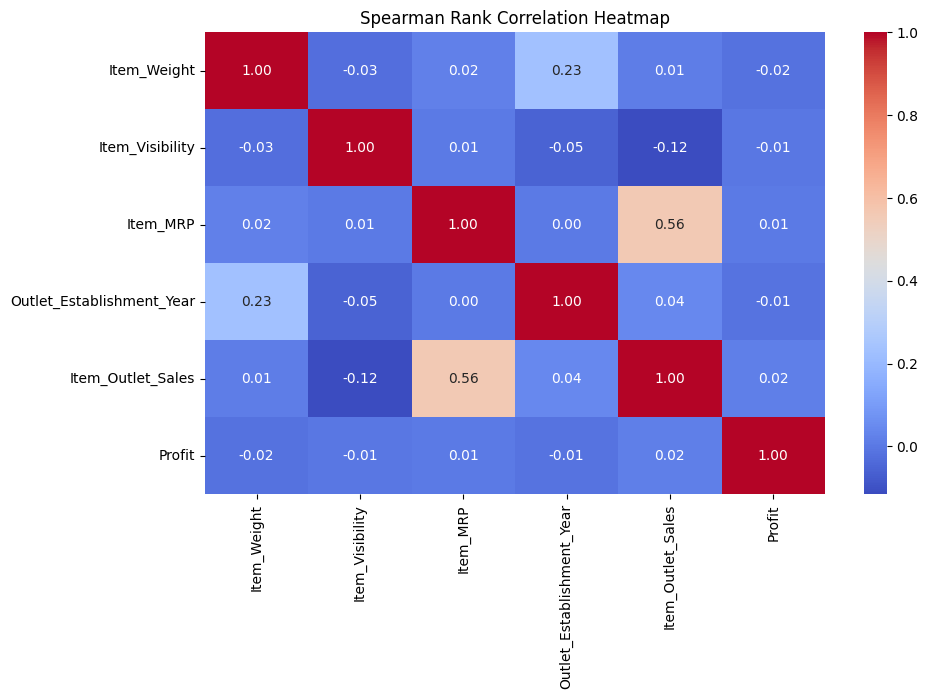

In [95]:
# Calculate Spearman correlation for all numerical columns
spearman_matrix = numeric_data.corr(method="spearman")

# Display heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(spearman_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Spearman Rank Correlation Heatmap")
plt.show()

#Pearson Correlation Analysis

In [96]:
from scipy.stats import pearsonr
# Select numerical columns from the dataset
numeric_data = df.select_dtypes(include=np.number)

print("Numerical Columns:")
print(numeric_data.columns)

Numerical Columns:
Index(['Item_Weight', 'Item_Visibility', 'Item_MRP',
       'Outlet_Establishment_Year', 'Item_Outlet_Sales', 'Profit'],
      dtype='object')


In [97]:
# Select the first two numerical columns
x = numeric_data.columns[0]
y = numeric_data.columns[1]

# Remove missing values
data = numeric_data[[x, y]].dropna()

# Calculate Pearson correlation
correlation, p_value = pearsonr(data[x], data[y])

print("Variable 1:", x)
print("Variable 2:", y)
print("Pearson Correlation:", round(correlation, 4))
print("P-value:", round(p_value, 4))

Variable 1: Item_Weight
Variable 2: Item_Visibility
Pearson Correlation: -0.0493
P-value: 0.0


In [98]:
if correlation > 0:
    print("Positive linear relationship.")
elif correlation < 0:
    print("Negative linear relationship.")
else:
    print("No linear correlation.")

if p_value < 0.05:
    print("The relationship is statistically significant.")
else:
    print("The relationship is not statistically significant.")

Negative linear relationship.
The relationship is statistically significant.


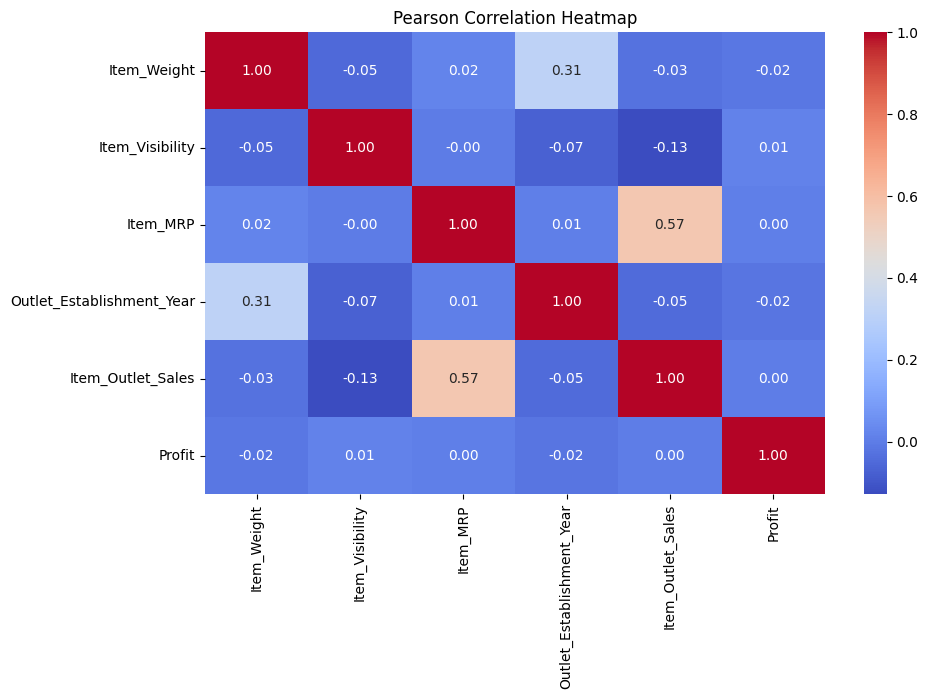

In [99]:
# Calculate Pearson correlation matrix
pearson_matrix = numeric_data.corr(method="pearson")

# Display heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(pearson_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Pearson Correlation Heatmap")
plt.show()

#Import Libraries and Prepare Data

In [113]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Remove unnecessary identifier columns
data = df.drop(columns=["Item_Identifier", "Outlet_Identifier"], errors="ignore")

# Fill missing values
for col in data.columns:
    if data[col].dtype == "object":
        data[col] = data[col].fillna(data[col].mode()[0])
    else:
        data[col] = data[col].fillna(data[col].median())

# Encode categorical columns
data = pd.get_dummies(data, drop_first=True)

# Select target and features
target = "Item_Outlet_Sales"
features = [col for col in data.columns if col != target]

X = data[features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Features:", len(features))
print("Target:", target)

Features: 31
Target: Item_Outlet_Sales


#All Regression Models


REGRESSION MODEL COMPARISON
                   Model      MAE         MSE     RMSE  R2 Score
       Linear Regression  793.035 1147597.837 1071.260     0.578
        Ridge Regression  793.021 1147585.123 1071.254     0.578
        Lasso Regression  792.744 1146868.614 1070.920     0.578
Decision Tree Regression 1012.433 2125339.040 1457.854     0.218
Random Forest Regression  771.071 1212975.990 1101.352     0.554

Best Model: Lasso Regression
Best R2 Score: 0.578


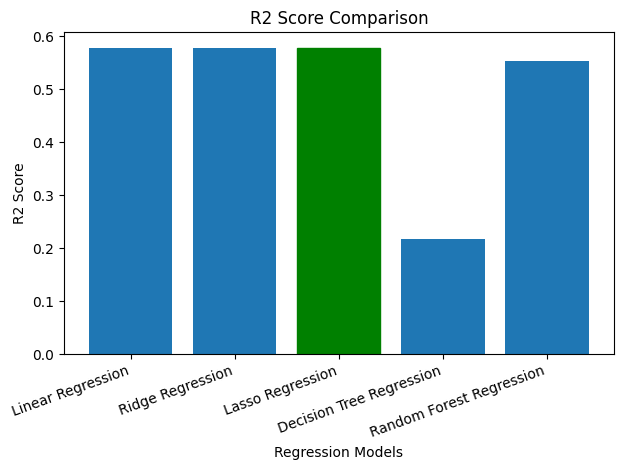


Best model saved successfully!
Feature columns saved successfully!


In [131]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare data
data = df.drop(
    columns=["Item_Identifier", "Outlet_Identifier", "Profit"],
    errors="ignore"
)

data = data.dropna(subset=["Item_Outlet_Sales"])

for col in data.columns:
    if data[col].dtype == "object":
        data[col] = data[col].fillna(data[col].mode()[0])
    else:
        data[col] = data[col].fillna(data[col].median())

# Separate input and target
X = pd.get_dummies(
    data.drop(columns=["Item_Outlet_Sales"]),
    drop_first=True
)

y = data["Item_Outlet_Sales"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale data for Ridge and Lasso
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train models
linear_model = LinearRegression()
ridge_model = Ridge()
lasso_model = Lasso(max_iter=10000)
tree_model = DecisionTreeRegressor(random_state=42)
forest_model = RandomForestRegressor(
    n_estimators=100, random_state=42, n_jobs=-1
)

linear_model.fit(X_train, y_train)
ridge_model.fit(X_train_scaled, y_train)
lasso_model.fit(X_train_scaled, y_train)
tree_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

# Generate predictions
linear_pred = linear_model.predict(X_test)
ridge_pred = ridge_model.predict(X_test_scaled)
lasso_pred = lasso_model.predict(X_test_scaled)
tree_pred = tree_model.predict(X_test)
forest_pred = forest_model.predict(X_test)

# Store predictions
predictions_dict = {
    "Linear Regression": linear_pred,
    "Ridge Regression": ridge_pred,
    "Lasso Regression": lasso_pred,
    "Decision Tree Regression": tree_pred,
    "Random Forest Regression": forest_pred
}

# Compare model scores
results = []

for name, predictions in predictions_dict.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print("\nREGRESSION MODEL COMPARISON")
print(results_df.round(3).to_string(index=False))

# Find the best model using highest R2 score
best_index = results_df["R2 Score"].idxmax()
best_name = results_df.loc[best_index, "Model"]

trained_models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model,
    "Decision Tree Regression": tree_model,
    "Random Forest Regression": forest_model
}

best_model = trained_models[best_name]

print("\nBest Model:", best_name)
print("Best R2 Score:", round(results_df.loc[best_index, "R2 Score"], 3))

# Plot R2 scores
bars = plt.bar(results_df["Model"], results_df["R2 Score"])

for i, name in enumerate(results_df["Model"]):
    if name == best_name:
        bars[i].set_color("green")

plt.title("R2 Score Comparison")
plt.xlabel("Regression Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Save best model and feature columns
joblib.dump(best_model, "best_model.pkl")
joblib.dump(list(X.columns), "model_columns.pkl")

# Save scaler if Ridge or Lasso is the best model
if best_name in ["Ridge Regression", "Lasso Regression"]:
    joblib.dump(scaler, "scaler.pkl")

print("\nBest model saved successfully!")
print("Feature columns saved successfully!")
